# TP — Markowitz portfolio optimisation on the CAC 40

**Goal of the session.** Starting from 5 years of daily prices of CAC 40 stocks (end 2011 → end 2016), we will:

1. compute **daily returns** and **descriptive statistics** (annualised mean, volatility, skewness, kurtosis…);
2. study the **correlation structure** between stocks (the key ingredient of diversification);
3. build a **market proxy** (an equally-weighted, *non-rebalanced* portfolio whose weights drift with prices) and estimate the **CAPM** betas and expected returns;
4. solve the **Markowitz mean–variance problem** numerically (minimum-variance portfolio, long-only);
5. trace the **efficient frontier**, locate the **global minimum variance (GMV)** portfolio, the **tangency (max-Sharpe)** portfolio and draw the **Capital Market Line (CML)**.

### Notation used throughout

| Symbol | Meaning |
|---|---|
| $P_{i,t}$ | closing price of stock $i$ on day $t$ |
| $R_{i,t}$ | simple daily return of stock $i$ on day $t$ |
| $N$ | number of stocks, $T$ number of daily observations |
| $w = (w_1,\dots,w_N)^\top$ | portfolio weights (fraction of wealth invested in each stock) |
| $\mu = (\mu_1,\dots,\mu_N)^\top$ | vector of (annualised) expected returns |
| $\Sigma$ | (annualised) variance–covariance matrix, $\Sigma_{ij} = \sigma_{ij} = \operatorname{Cov}(R_i,R_j)$ |
| $\sigma_i$ | volatility (standard deviation) of stock $i$ |
| $r_f$ | annual risk-free rate (here $1\%$) |
| $\mathbf 1$ | vector of ones of size $N$ |

Convention: **252 trading days per year** are used to annualise daily quantities.

## 0. Libraries

- `pandas`: tabular data (prices and returns are `DataFrame`s indexed by dates, one column per ticker).
- `numpy`: linear algebra (matrix products $w^\top \Sigma w$, square roots…).
- `matplotlib.pyplot`: charts (efficient frontier, portfolio composition).
- `scipy.optimize.minimize`: numerical optimiser used to solve the Markowitz problem (method **SLSQP**, which handles equality constraints and bounds).
- `typing`: only used for type hints in function signatures (`Dict`, `List`…), it has no effect at run time.

In [3]:
import pandas as pd
from typing import Dict, Tuple, List, Optional
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from matplotlib.figure import Figure

## 1. Loading the data

The Excel file `data_CAC.xlsx` contains a sheet `Prices` with:
- one row per trading day (column `Dates`, used as index → `index_col="Dates"`),
- one column per CAC 40 constituent (closing prices).

We keep the window **30/12/2011 → 30/12/2016** with `.loc["2011-12-30":"2016-12-30", :]`. With label-based slicing on a `DatetimeIndex`, **both bounds are included**. This is about 5 years, i.e. roughly $5 \times 252 \approx 1\,280$ trading days.

> Why 5 years? Mean–variance inputs ($\mu$, $\Sigma$) are estimated from history: a too short window gives very noisy estimates, a too long one mixes different market regimes. 3–5 years of daily data is a common compromise.

In [4]:
df_CAC = pd.read_excel("data_CAC.xlsx",sheet_name="Prices",index_col="Dates").loc["2011-12-30":"2016-12-30",:]

In [5]:
df_CAC

,OR FP Equity,DG FP Equity,STLA FP Equity,URW NA Equity,TTE FP Equity,AI FP Equity,DSY FP Equity,CS FP Equity,ERF FP Equity,BNP FP Equity,...,VIE FP Equity,SAN FP Equity,GLE FP Equity,SU FP Equity,AIR FP Equity,LR FP Equity,ACA FP Equity,RI FP Equity,STM FP Equity,WLN FP Equity
Dates,,,,,,,,,,,,,,,,,,,,,
2011-12-30,80.70,33.760,NaN,138.90,39.500,63.5925,6.193,10.045,5.633,30.350,...,8.1656,56.75,17.205,40.680,24.150,24.850,4.360,71.66,4.591,NaN
2012-01-02,81.80,34.450,NaN,137.80,40.000,64.6170,6.285,10.430,5.750,31.290,...,8.6149,57.42,17.685,41.560,24.500,25.160,4.433,72.47,4.703,NaN
2012-01-03,82.12,34.755,NaN,138.25,40.445,64.8432,6.263,10.580,5.937,31.335,...,8.5194,57.29,17.600,43.260,24.500,25.305,4.433,72.06,4.946,NaN
2012-01-04,81.33,34.550,NaN,136.60,40.135,64.4308,6.182,10.400,5.750,30.650,...,8.1829,56.21,17.000,42.080,24.565,25.160,4.300,71.62,4.791,NaN
2012-01-05,81.42,34.060,NaN,134.45,39.860,63.2998,6.195,9.890,5.661,29.000,...,7.9168,55.50,16.080,42.505,24.890,24.770,4.076,71.53,4.726,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2016-12-26,172.55,64.480,NaN,221.55,48.360,86.9421,14.372,24.050,40.090,61.170,...,15.3737,75.86,46.810,65.150,62.900,54.020,11.905,102.05,10.745,26.215
2016-12-27,172.70,64.530,NaN,222.90,48.375,87.1074,14.400,24.165,40.235,60.680,...,15.4990,76.22,46.810,65.420,62.920,54.120,11.880,102.55,10.840,26.505
2016-12-28,172.40,64.190,NaN,220.20,48.720,87.1901,14.486,23.995,40.540,60.650,...,15.4460,76.15,46.740,65.610,62.720,54.000,11.880,102.35,10.795,26.570


## 2. From prices to returns

### 2.1 Simple (arithmetic) returns

For each stock $i$ and each day $t$:

$$R_{i,t} = \frac{P_{i,t} - P_{i,t-1}}{P_{i,t-1}} = \frac{P_{i,t}}{P_{i,t-1}} - 1$$

### 2.2 Why returns and not prices?

- Prices are **non-stationary** (they trend, their level depends on the number of shares…); returns are (approximately) stationary, so their mean and variance can be estimated meaningfully.
- Returns are **unit-free**: a stock at 5 € and one at 500 € become comparable.

### 2.3 Why *simple* returns (and not log returns)?

Simple returns **aggregate linearly across assets**: if a portfolio holds weights $w_i$ at the start of day $t$,

$$R_{p,t} = \sum_{i=1}^N w_{i}\,R_{i,t} = w^\top R_t$$

This linearity is exactly what Markowitz theory relies on ($E[R_p] = w^\top\mu$, $\operatorname{Var}(R_p)=w^\top\Sigma w$). Log returns $r_{i,t} = \ln(P_{i,t}/P_{i,t-1})$ aggregate nicely **over time** (they add up) but **not across assets**.

### 2.4 Cleaning steps

1. **Remove stocks with missing prices** (`dropna(axis=1)`): a stock that was not listed during the whole window (IPO, entry/exit of the index…) would have `NaN`s. Dropping the column keeps a *balanced* panel, so that all covariances are computed on the same dates.
2. **Compute returns** (`pct_change()`): implements the formula above column by column.
3. **Remove the first row** (`dropna()`): the first date has no $P_{t-1}$, so its return is `NaN`.

> ⚠️ Dropping stocks that did not survive the whole period introduces a (small) **survivorship bias**: we only keep stocks that existed for the 5 years.

In [6]:
def calculer_rendements(df: pd.DataFrame) -> pd.DataFrame:
    """
    Compute daily returns for all stocks
    
    Parameters:
        df (pd.DataFrame): DataFrame with dates as index and tickers as columns
    
    Returns:
        pd.DataFrame: DataFrame of daily returns
    """
    rendements = df.dropna(axis=1).pct_change()
    return rendements.dropna()

## 3. Descriptive statistics

Let $T$ be the number of daily returns of stock $i$.

### 3.1 Daily mean and volatility

$$\bar R_i = \frac1T \sum_{t=1}^T R_{i,t}, \qquad
\hat\sigma_i = \sqrt{\frac{1}{T-1}\sum_{t=1}^T \left(R_{i,t}-\bar R_i\right)^2}$$

(`pandas.std()` uses the unbiased $T-1$ denominator by default.)

### 3.2 Annualisation (the "square-root-of-time" rule)

Assume daily returns are **i.i.d.** and small. Over one year of 252 days, the annual return is approximately the sum of the daily returns:

$$R^{\text{year}} \approx \sum_{t=1}^{252} R_t
\;\Rightarrow\;
E[R^{\text{year}}] = 252\,E[R_t], \qquad
\operatorname{Var}(R^{\text{year}}) = \sum_{t=1}^{252}\operatorname{Var}(R_t) = 252\,\sigma^2_{\text{daily}}$$

(the variance of a sum of **independent** variables is the sum of the variances — all covariance terms vanish). Hence:

$$\boxed{\mu^{\text{ann}} = 252\,\bar R}, \qquad \boxed{\sigma^{\text{ann}} = \sqrt{252}\,\hat\sigma}$$

The mean scales with **time**, the volatility with the **square root of time**.

### 3.3 Higher moments: is the distribution Gaussian?

**Skewness** (asymmetry):
$$\text{Skew}_i = \frac{\frac1T\sum_t (R_{i,t}-\bar R_i)^3}{\hat\sigma_i^3}$$
- $=0$ for a symmetric distribution (e.g. Gaussian); $<0$: long left tail (big crashes more frequent than big rallies), typical of equities.

**Kurtosis** (thickness of the tails). `pandas.kurtosis()` returns the **excess** kurtosis (Fisher definition):
$$\text{Kurt}_i = \frac{\frac1T\sum_t (R_{i,t}-\bar R_i)^4}{\hat\sigma_i^4} - 3$$
- $=0$ for a Gaussian; $>0$ (**leptokurtic**, "fat tails"): extreme returns are much more frequent than the normal law predicts. Daily stock returns typically show excess kurtosis of 3 to 10 or more.

**Min / max daily return**: the worst and best day of the period — a quick check of extreme risk (and of possible data errors).

> Why do we care? Markowitz only uses the **first two moments** ($\mu$ and $\Sigma$). Large skewness / kurtosis tell us that variance is an incomplete measure of risk.

In [7]:
def calculer_stats_descriptives(rendements: pd.DataFrame) -> pd.DataFrame:
    """
    Compute descriptive statistics for each stock
    
    Parameters:
        rendements (pd.DataFrame): DataFrame of daily returns
    
    Returns:
        pd.DataFrame: DataFrame of descriptive statistics
    """
    stats = pd.DataFrame()
    stats['Annualized mean return'] = rendements.mean() * 252
    stats['Annualized volatility'] = rendements.std() * np.sqrt(252)
    stats['Skewness'] = rendements.skew()
    stats['Kurtosis'] = rendements.kurtosis()
    stats['Minimum return'] = rendements.min()
    stats['Maximum return'] = rendements.max()
    return stats

## 4. Covariance and correlation matrices

### 4.1 Definitions

Sample covariance between stocks $i$ and $j$:
$$\hat\sigma_{ij} = \frac{1}{T-1}\sum_{t=1}^T (R_{i,t}-\bar R_i)(R_{j,t}-\bar R_j)$$

Correlation (covariance normalised to lie in $[-1,1]$):
$$\rho_{ij} = \frac{\hat\sigma_{ij}}{\hat\sigma_i\,\hat\sigma_j}$$

In matrix form, with $D = \operatorname{diag}(\sigma_1,\dots,\sigma_N)$ and $C$ the correlation matrix: $\;\Sigma = D\,C\,D$.

### 4.2 Why correlation is the heart of diversification

For two assets with weights $w_1, w_2$:
$$\sigma_p^2 = w_1^2\sigma_1^2 + w_2^2\sigma_2^2 + 2\,w_1w_2\,\rho_{12}\,\sigma_1\sigma_2$$
- If $\rho_{12}=1$: $\sigma_p = w_1\sigma_1 + w_2\sigma_2$ → **no diversification benefit**.
- If $\rho_{12}<1$: $\sigma_p < w_1\sigma_1 + w_2\sigma_2$ → the portfolio is **less risky than the average of its components**.

For an equally-weighted portfolio of $N$ assets, with average variance $\overline{\sigma^2}$ and average covariance $\overline{\sigma_{ij}}$:
$$\sigma_p^2 = \frac1N\,\overline{\sigma^2} + \frac{N-1}{N}\,\overline{\sigma_{ij}} \;\xrightarrow[N\to\infty]{}\; \overline{\sigma_{ij}}$$
The **idiosyncratic** risk vanishes, only the **systematic** (market) risk — the average covariance — remains. This is precisely the risk measured by the CAPM beta in the next section.

> Correlations between CAC 40 stocks are typically positive (≈ 0.3 – 0.7): they share a common market factor. Note that correlation is **scale-free**: daily or annualised returns give the same correlation matrix.

In [8]:
def calculer_matrice_correlation(rendements: pd.DataFrame) -> pd.DataFrame:
    """
    Compute the correlation matrix between stocks
    
    Parameters:
        rendements (pd.DataFrame): DataFrame of daily returns
    
    Returns:
        pd.DataFrame: Correlation matrix
    """
    return rendements.corr()


## 5. CAPM with a "buy-and-hold" market proxy

### 5.1 The CAPM in one formula

The Capital Asset Pricing Model states that the expected return of an asset only rewards its **systematic risk**, measured by its **beta** with respect to the market portfolio $m$:

$$\boxed{E[R_i] = r_f + \beta_i\,\big(E[R_m] - r_f\big)}, \qquad \boxed{\beta_i = \frac{\operatorname{Cov}(R_i, R_m)}{\operatorname{Var}(R_m)}}$$

- $E[R_m]-r_f$ is the **market risk premium**;
- $\beta_i>1$: aggressive stock (amplifies market moves), $\beta_i<1$: defensive stock, $\beta_m = 1$ by construction;
- the line $\beta \mapsto r_f + \beta(E[R_m]-r_f)$ is the **Security Market Line (SML)**.

### 5.2 Which "market" portfolio?

We do not use the official CAC 40 index. Instead we **build our own market proxy** from the stocks of the sample:
- on the first day, **equal weights**: $w_{i,1} = 1/N$;
- then **no rebalancing**: we buy once and hold. The number of shares of each stock is fixed, so the **weights drift** with relative performance: stocks that go up become a bigger part of the portfolio.

This "buy-and-hold" portfolio behaves like a real index (a cap-weighted index is also a buy-and-hold portfolio between two rebalancing dates).

### 5.3 Weight drift — step by step

Let $V_t$ be the portfolio value at the close of day $t$ and $w_{i,t}$ the weight of stock $i$ **at the start of day $t$** (i.e. at the close of $t-1$). The amount invested in stock $i$ at the start of day $t$ is $w_{i,t}V_{t-1}$.

**Step 1 — market return of day $t$** (linear aggregation of simple returns):
$$R_{m,t} = \sum_{i=1}^N w_{i,t}\,R_{i,t}$$

**Step 2 — portfolio value update:**
$$V_t = V_{t-1}\,(1+R_{m,t}), \qquad V_0 = 100$$

**Step 3 — value of each position at the close of day $t$:** each position grows with its own return,
$$\text{position}_{i} = w_{i,t}V_{t-1}\,(1+R_{i,t})$$

**Step 4 — new weights = position / total value (normalisation):**
$$w_{i,t+1} = \frac{w_{i,t}\,(1+R_{i,t})}{\sum_{j=1}^N w_{j,t}\,(1+R_{j,t})} = \frac{w_{i,t}\,(1+R_{i,t})}{1+R_{m,t}}$$

(the denominator is exactly $1+R_{m,t}$ because $\sum_j w_{j,t}=1$). Dividing by the sum guarantees $\sum_i w_{i,t+1} = 1$.

⚠️ **The order matters**: the return of day $t$ must be computed with the weights *before* they are updated with day $t$'s returns (Step 1 before Step 4). Using already-drifted weights would mean using day $t$'s returns to choose day $t$'s portfolio (look-ahead bias).

#### Numerical example (2 stocks)

| | $w_A$ | $w_B$ | $R_A$ | $R_B$ | $R_m$ |
|---|---|---|---|---|---|
| Day 1 | 0.50 | 0.50 | +10% | −10% | $0.5(0.10)+0.5(-0.10) = 0\%$ |
| Drift | $\frac{0.5\times1.1}{1.00}=0.55$ | $\frac{0.5\times0.9}{1.00}=0.45$ | | | |
| Day 2 | 0.55 | 0.45 | +10% | 0% | $0.55(0.10)+0.45(0) = 5.5\%$ |

Stock A, which outperformed on day 1, weighs more on day 2.

**Comparison with a rebalanced portfolio**: with *constant* weights $1/N$ (daily rebalancing), Step 4 would be replaced by $w_{i,t+1}=1/N$ — this requires selling the winners and buying the losers every day.

### 5.4 Annualised market return (geometric)

Over $T$ days, the cumulative growth of the market portfolio is $\prod_{t=1}^T(1+R_{m,t}) = V_T/V_0$. The **annualised (geometric / compound) return** is the constant annual rate giving the same final wealth:

$$\big(1+R_m^{\text{ann}}\big)^{T/252} = \prod_{t=1}^{T}(1+R_{m,t})
\quad\Longrightarrow\quad
\boxed{R_m^{\text{ann}} = \Big(\prod_{t=1}^{T}(1+R_{m,t})\Big)^{252/T} - 1}$$

(This is the CAGR. It is always $\le$ the arithmetic annualised mean $252\,\bar R_m$; to a first order, geometric $\approx$ arithmetic $-\sigma^2/2$.)

### 5.5 Beta estimation

For each stock, with the daily series $R_{i,t}$ and $R_{m,t}$:
$$\hat\beta_i = \frac{\widehat{\operatorname{Cov}}(R_i,R_m)}{\widehat{\operatorname{Var}}(R_m)}$$

- This is exactly the **OLS slope** of the regression $R_{i,t} = \alpha_i + \beta_i R_{m,t} + \varepsilon_{i,t}$.
- Betas are **unit-free**: computed on daily or annualised returns, the factor 252 cancels between numerator and denominator.
- Strictly, the CAPM regression uses **excess returns** $R-r_f$; with a daily risk-free rate of $1\%/252 \approx 0.004\%$, the difference is negligible.
- Sanity check: the weighted average of the betas (with market weights) equals 1.

### 5.6 CAPM expected returns

$$\text{Risk premium} = R_m^{\text{ann}} - r_f, \qquad E[R_i]^{\text{CAPM}} = r_f + \hat\beta_i\,\big(R_m^{\text{ann}} - r_f\big)$$

These "equilibrium" expected returns can be compared to the historical means of Section 3: a stock whose historical mean is above its CAPM return had a positive **alpha** over the period.

#### Implementation notes (solution)

- `pd.Series(index=rendements.index)` creates an empty (NaN) series that is filled day by day inside the loop.
- `(rendements.loc[jour] * poids_marche).sum()` is $\sum_i w_{i,t}R_{i,t}$: pandas aligns the two Series on the tickers.
- `poids_marche * (1 + rendements.loc[jour])` then `/= poids_marche.sum()` is exactly Step 3 + Step 4.
- `(1 + rm_quotidien).prod() ** (252 / len(rm_quotidien)) - 1` is the CAGR formula of 5.4.
- `np.cov(x, y)` returns the $2\times2$ matrix $\begin{pmatrix}\operatorname{Var}(x)&\operatorname{Cov}(x,y)\\ \operatorname{Cov}(x,y)&\operatorname{Var}(y)\end{pmatrix}$, so `[0, 1]` picks the covariance.
- Small detail: `np.cov` uses the $T-1$ denominator while `np.var` uses $T$ by default, so betas are inflated by a factor $T/(T-1) \approx 1.0008$ — negligible here, but `np.var(rm_quotidien, ddof=1)` would be fully consistent.
- `valeurs_portefeuille` is only used for illustration (it is not used in the beta computation); note that it starts compounding at the second day.

In [9]:
def calculer_capm(rendements: pd.DataFrame, rf: float = 0.01) -> pd.DataFrame:
    """
    Compute CAPM for each stock using a market return estimate 
    without rebalancing from initially equal weights.
       
    Parameters:
        rendements (pd.DataFrame): DataFrame of daily returns.
        rf (float): Annualized risk-free rate.
    
    Returns:
        pd.DataFrame: DataFrame containing betas and expected returns.
    """
    # Initialize equal weights on the first day
    nb_actions = len(rendements.columns)
    poids_marche = pd.Series(1 / nb_actions, index=rendements.columns)
    
    # Compute the market return letting weights drift
    rm_quotidien = pd.Series(index=rendements.index)  # instantiation of the market return vector
    valeurs_portefeuille = [100]  # initial value of the market portfolio

    for i, jour in enumerate(rendements.index):

        # initializes the market return with the weights vector
        rm_quotidien[jour] = (rendements.loc[jour] * poids_marche).sum()
        if i > 0:
            # Update portfolio values without rebalancing
            valeurs_portefeuille.append(valeurs_portefeuille[-1] * (1 + rm_quotidien[jour]))
            
        # compute weight drift (weights drift according to asset performance)  
        poids_marche = poids_marche * (1 + rendements.loc[jour])
        poids_marche /= poids_marche.sum()  # normalize so that weights sum to 1
    
    # Compute annualized return
    rm_annuel = (1 + rm_quotidien).prod() ** (252 / len(rm_quotidien)) - 1  
    
    # Compute betas
    betas = {}
    for stock in rendements.columns:
        covar = np.cov(rendements[stock], rm_quotidien)[0, 1] 
        var_rm = np.var(rm_quotidien)
        beta = covar / var_rm
        betas[stock] = beta
    
    # Compute risk premium
    risk_premium = rm_annuel - rf
    
    # Compute expected returns
    expected_returns = {}
    for action, beta in betas.items():
        expected_returns[action] = rf + beta * risk_premium
    
    return pd.DataFrame({
        'Beta': betas,
        'Expected return': expected_returns,
        'Risk premium': risk_premium,
        'Market return': rm_annuel
    })

## 6. Markowitz mean–variance optimisation

### 6.1 Inputs

Annualised (cf. Section 3.2):
$$\mu = 252\,\bar R \in \mathbb R^N, \qquad \Sigma = 252\,\hat\Sigma^{\text{daily}} \in \mathbb R^{N\times N}$$

We use the **arithmetic** mean here (not the geometric one): the expected return of a portfolio is then exactly linear in the weights. This is the approximation "returns are small and i.i.d."

### 6.2 Portfolio return and variance

For weights $w$:
$$E[R_p] = \sum_i w_i\mu_i = w^\top\mu$$
$$\sigma_p^2 = \operatorname{Var}\Big(\sum_i w_iR_i\Big) = \sum_{i=1}^N\sum_{j=1}^N w_iw_j\,\sigma_{ij} = w^\top\Sigma\,w$$
(the double sum contains the $N$ variances on the diagonal and the $N(N-1)$ covariance terms off the diagonal). In numpy: `w @ Sigma @ w` or `np.dot(w.T, np.dot(Sigma, w))`.

### 6.3 The optimisation problem

$$
\begin{aligned}
\min_{w\in\mathbb R^N}\quad & w^\top\Sigma\,w &&\text{(minimise risk)}\\
\text{s.t.}\quad & \mathbf 1^\top w = \textstyle\sum_i w_i = 1 &&\text{(fully invested — budget constraint)}\\
& 0 \le w_i \le 1 \;\; \forall i &&\text{(long-only, no leverage)}\\
& w^\top\mu = \mu^\ast &&\text{(optional: target return)}
\end{aligned}
$$

- **Without the target-return constraint** → the solution is the **Global Minimum Variance (GMV)** portfolio, the least risky fully-invested long-only portfolio.
- **With a target $\mu^\ast$** → the least risky portfolio achieving $\mu^\ast$; it is one point of the **minimum-variance frontier** (Section 7).

### 6.4 Why a numerical solver?

Without the bounds (short selling allowed), the GMV has a closed form obtained with a Lagrangian:
$$\mathcal L = w^\top\Sigma w - \lambda(\mathbf 1^\top w - 1)
\;\Rightarrow\; 2\Sigma w = \lambda\mathbf 1
\;\Rightarrow\; w_{\text{GMV}} = \frac{\Sigma^{-1}\mathbf 1}{\mathbf 1^\top\Sigma^{-1}\mathbf 1}$$
With the **inequality constraints** $0\le w_i\le1$, some weights hit 0 and there is no closed form → we solve the **quadratic program** numerically with `scipy.optimize.minimize(method="SLSQP")` (Sequential Least SQuares Programming):

- `fun`: the objective $w \mapsto w^\top\Sigma w$;
- `x0`: starting point, here equal weights $1/N$ (feasible and neutral);
- `bounds`: one `(0, 1)` pair per asset;
- `constraints`: list of dicts; `{'type': 'eq', 'fun': f}` means **$f(w) = 0$** is imposed. So `np.sum(x) - 1` encodes $\sum w_i = 1$, and `portfolio_expected_return(x) - target_return` encodes $w^\top\mu=\mu^\ast$.

`result.x` contains the optimal weights; the function then returns $w^\ast$, $E[R_p]=w^{\ast\top}\mu$ and $\sigma_p = \sqrt{w^{\ast\top}\Sigma w^\ast}$.

> Note: the argument `rf` is not used in this function (minimising variance does not depend on $r_f$); it only matters for the Sharpe ratio, in the next section.

In [10]:
def optimisation_portefeuille(rendements: pd.DataFrame, rf: float = 0.01, target_return: float = None):
    """
    Compute the minimum variance portfolio in the Markowitz sense
    """
    n_assets = len(rendements.columns)
    # NOTE: assumption that returns are small and iid: approximation of the geometric mean by the arithmetic mean
    mu = rendements.mean() * 252  # annualized mean
    cov_matrix = rendements.cov() * 252  # annualized variance-covariance matrix
    
    def portfolio_variance(weights):
        return np.dot(weights.T, np.dot(cov_matrix, weights))
    
    def portfolio_expected_return(weights):
        return np.sum(mu * weights)
    
    # declaration of optimization constraints (portfolio 100% invested + target return if provided by the user)
    constraints = [
        {'type': 'eq', 'fun': lambda x: np.sum(x) - 1}
    ]
    
    if target_return is not None:
        constraints.append(
            {'type': 'eq', 'fun': lambda x: portfolio_expected_return(x) - target_return}
        )
    
    # bounds for asset weights
    bounds = tuple((0, 1) for _ in range(n_assets))
    weights_init = np.array([1 / n_assets] * n_assets)
    
    result = minimize(portfolio_variance, weights_init,
                     method='SLSQP',
                     bounds=bounds,
                     constraints=constraints)
    
    weights_opt = result.x
    rendement_portefeuille = portfolio_expected_return(weights_opt)
    volatilite_portefeuille = np.sqrt(portfolio_variance(weights_opt))
    
    return {
        'Weights': pd.Series(weights_opt, index=rendements.columns),
        'Expected return': rendement_portefeuille,
        'Volatility': volatilite_portefeuille
    }


## 7. The efficient frontier, the tangency portfolio and the CML

### 7.1 What is the efficient frontier?

The **minimum-variance frontier** is the set of portfolios that have the lowest volatility for each level of expected return. In the $(\sigma, E[R])$ plane it is a curve shaped like a "bullet" (a hyperbola when short sales are allowed):
- its leftmost point is the **GMV** portfolio;
- the **upper branch** (above the GMV) is the **efficient frontier**: no other portfolio offers a higher return for the same risk;
- the **lower branch** is **inefficient**: for the same volatility, the portfolio on the upper branch gives a higher return. A rational (risk-averse) investor never chooses it.

### 7.2 Procedure to compute it — step by step

**Step 1 — grid of target returns.** In a long-only, fully-invested portfolio, $w^\top\mu$ is a *convex combination* of the $\mu_i$, hence
$$\min_i \mu_i \;\le\; w^\top\mu \;\le\; \max_i \mu_i .$$
Any target outside this interval is infeasible. We therefore build `n_portfolios` (= 50) equally spaced targets:
$$\mu^\ast_k = \mu_{\min} + \frac{k}{n-1}(\mu_{\max}-\mu_{\min}),\qquad k = 0,\dots,n-1$$
This is what `np.linspace(start, stop, num)` returns.

**Step 2 — one optimisation per target.** For each $\mu^\ast_k$, solve the problem of Section 6.3 *with* the target constraint → weights $w_k^\ast$ and volatility $\sigma_k = \sqrt{w_k^{\ast\top}\Sigma w_k^\ast}$. The point $(\sigma_k, \mu^\ast_k)$ is on the frontier.

**Step 3 — Sharpe ratio of each frontier portfolio:**
$$S_k = \frac{\mu^\ast_k - r_f}{\sigma_k}$$
(excess return per unit of risk).

**Step 4 — GMV portfolio**: the grid point with the smallest volatility, $k_{\text{GMV}} = \arg\min_k \sigma_k$.

**Step 5 — tangency portfolio**: the grid point with the highest Sharpe ratio, $k_T = \arg\max_k S_k$.

**Step 6 — split the curve** at $k_{\text{GMV}}$: points with $k \le k_{\text{GMV}}$ form the inefficient lower branch (red), points with $k \ge k_{\text{GMV}}$ the efficient frontier (blue).

**Step 7 — add the Capital Market Line and the individual stocks** (below).

> The GMV and tangency portfolios found this way are only **approximations on the grid** (50 points). A finer grid, or a direct optimisation (minimise variance without target; maximise $S(w)$), would give them exactly.

### 7.3 Capital Market Line (CML)

Suppose the investor can also invest (or borrow) at the risk-free rate. Put a fraction $a$ in a risky portfolio $T$ and $1-a$ in the risk-free asset:
$$R = (1-a)\,r_f + a\,R_T
\;\Rightarrow\;
E[R] = r_f + a\,(E[R_T]-r_f), \qquad \sigma = a\,\sigma_T \;\;(\text{since } \sigma_{r_f}=0)$$
Eliminating $a = \sigma/\sigma_T$:
$$\boxed{E[R] = r_f + \frac{E[R_T]-r_f}{\sigma_T}\,\sigma}$$
This is a **straight line** from $(0, r_f)$ through $(\sigma_T, E[R_T])$, whose **slope is the Sharpe ratio of $T$**. The best line is the steepest one that still touches the feasible set: it is **tangent** to the efficient frontier, at the portfolio with the **maximum Sharpe ratio** → the *tangency portfolio*. In CAPM equilibrium, it is the market portfolio.

- $0<a<1$ (left of $T$): lend at $r_f$ (part of the wealth in cash);
- $a>1$ (right of $T$): borrow at $r_f$ to invest more than 100% in $T$ (leverage).

**Two-fund separation**: every investor holds a mix of the risk-free asset and the same tangency portfolio; only the proportion $a$ depends on their risk aversion. The CML dominates the risky efficient frontier everywhere except at the tangency point.

### 7.4 Individual stocks

Each stock $i$ is plotted at $(\sigma_i^{\text{ann}}, \mu_i^{\text{ann}}) = (\sqrt{252}\,\hat\sigma_i,\; 252\,\bar R_i)$. All of them lie **on or to the right of** the frontier: holding a single stock is never better than a diversified portfolio with the same expected return — the visual proof of diversification.

#### Implementation notes (solution)

- `returns_range = np.linspace(rendements.mean().min()*252, rendements.mean().max()*252, n_portfolios)` → Step 1.
- `optimisation_portefeuille(rendements, rf, target_return)` → Step 2; `result["Volatility"]` gives $\sigma_k$.
- The `assert` checks (to 2 decimals) that the solver did reach the target return, i.e. that the constraint is satisfied.
- `min_volatility` / `max_sharpe_ratio` are initialised at $+\infty$ / $-\infty$ so that the first portfolio always updates them (running $\arg\min$ / $\arg\max$).
- CML: `slope = (return_m - rf) / sigma_m`, then `cml_returns = rf + slope * sigma_range`.
- Stocks: `vols_actions = rendements.std() * np.sqrt(252)`, `returns_actions = rendements.mean() * 252`.

In [11]:
def tracer_frontiere_efficiente(
    rendements: pd.DataFrame, 
    rf: float = 0.01, 
    n_portfolios: int = 50
) -> Figure:
    """
    Plot the efficient frontier + the minimum variance and maximum Sharpe ratio portfolios
    
    Parameters:
        rendements (pd.DataFrame): DataFrame of daily returns
        rf (float): Annualized risk-free rate
        n_portfolios (int): Number of portfolios to compute
    
    Returns:
        Figure: Matplotlib figure of the efficient frontier
    """
    # create a linspace of length n_portfolios between the minimum and maximum annualized mean return
    returns_range = np.linspace(
        rendements.mean().min() * 252,  # lowest expected return
        rendements.mean().max() * 252,  # highest expected return
        n_portfolios  # number of points (50 by default)
    )
    
    volatilities = []
    returns_list = []
    sharpe_ratios = []
    
    min_volatility = float('inf')
    max_sharpe_ratio = -float('inf')
    min_volatility_portfolio = None
    max_sharpe_portfolio = None
    
    # successive portfolio optimizations for each target return
    for target_return in returns_range:
        # for each mean return, estimate a min-variance portfolio under a target return constraint
        result = optimisation_portefeuille(rendements, rf, target_return)
        weights = result["Weights"]
        portfolio_vol = result["Volatility"]
        assert round(target_return, 2) == round(result["Expected return"], 2)
        portfolio_return = target_return
        
        # compute Sharpe ratio for this portfolio
        sharpe_ratio = (portfolio_return - rf) / portfolio_vol
        
        volatilities.append(portfolio_vol)
        returns_list.append(portfolio_return)
        sharpe_ratios.append(sharpe_ratio)
        
        # check if this is the minimum variance portfolio
        if portfolio_vol < min_volatility:
            min_volatility = portfolio_vol
            min_volatility_portfolio = (portfolio_vol, portfolio_return)
        
        # check if this is the maximum Sharpe ratio portfolio
        if sharpe_ratio > max_sharpe_ratio:
            max_sharpe_ratio = sharpe_ratio
            max_sharpe_portfolio = (portfolio_vol, portfolio_return)
    
    # split the frontier into two segments, below and above the min-variance portfolio
    min_index = volatilities.index(min_volatility)
    volatilities_below = volatilities[:min_index + 1]
    returns_below = returns_list[:min_index + 1]
    volatilities_above = volatilities[min_index:]
    returns_above = returns_list[min_index:]
    
    plt.figure(figsize=(12, 8))
    # plot the part below min-variance in red and the part above in blue
    plt.plot(volatilities_below, returns_below, 'r-', label='Envelope of feasible portfolios')
    plt.plot(volatilities_above, returns_above, 'b-', label='Efficient frontier')
    
    # add the minimum variance portfolio (green point)
    if min_volatility_portfolio is not None:
        plt.scatter(min_volatility_portfolio[0], min_volatility_portfolio[1], 
                    c='green', marker='o', s=100, label='Minimum variance portfolio')
    
    # add the maximum Sharpe ratio portfolio (orange point)
    if max_sharpe_portfolio is not None:
        plt.scatter(max_sharpe_portfolio[0], max_sharpe_portfolio[1], 
                    c='orange', marker='o', s=100, label='Tangent portfolio (max Sharpe)')

    # === CML (Capital Market Line) ===
    if max_sharpe_portfolio is not None:
        rf_point = rf
        sigma_m = max_sharpe_portfolio[0]
        return_m = max_sharpe_portfolio[1]
    
        # pente de la CML = (E[Rm] - Rf) / σm
        slope = (return_m - rf_point) / sigma_m
    
        # on trace la CML de σ = 0 à un peu au-delà du σ du portefeuille tangent
        sigma_range = np.linspace(0, max(volatilities) * 1.3, 100)
        cml_returns = rf_point + slope * sigma_range
    
        plt.plot(sigma_range, cml_returns, color='darkorange', linestyle='-', linewidth=2,
                 label='Capital Market Line (CML)')
        
        # add a scatter plot of the 100% risk free portfolio
        plt.scatter(0, rf, c='black', marker='*', s=120, label='Risk-free asset')

    
    # add a scatter plot for the stocks in volatility/annualized return space
    vols_actions = rendements.std() * np.sqrt(252)
    returns_actions = rendements.mean() * 252
    plt.scatter(vols_actions, returns_actions, c='red', marker='o', label='Individual stocks')
    
    for i, txt in enumerate(rendements.columns):
        plt.annotate(txt, (vols_actions[i], returns_actions[i]))
    
    plt.xlabel('Annualized volatility')
    plt.ylabel('Expected annualized return')
    plt.title('Efficient Frontier, Minimum Variance Portfolio and Maximum Sharpe Ratio')
    plt.legend()
    plt.grid(True)
    
    return plt.gcf()  # .gcf() means "get current figure"


## 8. Portfolio composition chart

A bar chart of the optimal weights, sorted from the largest to the smallest (`sort_values(ascending=False)`).

What to look for when you read it:
- **Concentration**: long-only minimum-variance portfolios typically put most of the weight on a handful of stocks and **exactly 0** on many others (the bound $w_i \ge 0$ is *active* — a "corner solution").
- **Low-volatility and low-correlation stocks** are favoured by the GMV (it ignores expected returns entirely).
- Check that the weights are all in $[0,1]$ and sum to 1.

In [12]:
def graphique_composition_portefeuille(weights):
    """
    Display a bar chart showing the composition of the portfolio,
    sorted from the largest to the smallest weight.
    
    Parameters:
        weights (pd.Series): Vector of asset weights in the portfolio.
    """
    
    # Sort weights from largest to smallest
    sorted_weights = weights.sort_values(ascending=False)
    
    # Plot the chart
    plt.figure(figsize=(10, 6))
    sorted_weights.plot(kind='bar', color='skyblue', edgecolor='black')
    
    # Add titles and labels
    plt.title('Portfolio Composition', fontsize=16)
    plt.xlabel('Assets', fontsize=14)
    plt.ylabel('Weights', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    
    # Show the chart
    plt.tight_layout()
    plt.show()


## 9. Putting everything together: `main()`

`main()` runs the whole pipeline with $r_f = 1\%$:

1. `calculer_rendements` → daily returns $R_{i,t}$ (Section 2);
2. `calculer_stats_descriptives` → annualised mean / volatility, skewness, kurtosis, min, max (Section 3);
3. `calculer_matrice_correlation` → correlation matrix $\rho_{ij}$ (Section 4);
4. `calculer_capm` → drifting-weights market proxy, $\beta_i$ and CAPM expected returns (Section 5);
5. `optimisation_portefeuille` **without target** → GMV portfolio + composition chart (Sections 6 and 8);
6. `tracer_frontiere_efficiente` → efficient frontier, GMV, tangency portfolio, CML and stocks (Section 7).

It returns a dictionary with the main results so that they can be reused afterwards (e.g. `res = main(); res["capm"]`).

In [13]:
def main() -> Dict[str, pd.DataFrame]:
    """
    Main function that executes the complete analysis
    
    Returns:
        Dict[str, pd.DataFrame]: Dictionary containing all analysis results
    """
    
    r_f = 0.01
    
    # Create a synthetic DataFrame
    df = df_CAC.copy(deep=True)
    
    print("1. Compute returns")
    print("-" * 50)
    rendements = calculer_rendements(df)
    
    print("\n2. Descriptive statistics")
    print("-" * 50)
    stats = calculer_stats_descriptives(rendements)
    print("\nStatistics by stock:")
    print(stats)
    
    print("\n3. Correlation matrix")
    print("-" * 50)
    corr = calculer_matrice_correlation(rendements)
    
    print("\n4. CAPM analysis")
    print("-" * 50)
    capm_results = calculer_capm(rendements, r_f)
    print("\nCAPM results:")
    print(capm_results)
    
    print("\n5. Optimal portfolio")
    print("-" * 50)
    ptf_optimal = optimisation_portefeuille(rendements, r_f)
    print("\nOptimal weights:")
    print(ptf_optimal)
    graphique_composition_portefeuille(ptf_optimal["Weights"])
    
    print("\n6. Efficient frontier visualization")
    print("-" * 50)
    fig = tracer_frontiere_efficiente(rendements, r_f)
    plt.show()

    return {
        'returns': rendements,
        'stats': stats,
        'capm': capm_results,
        'weights_optimal': ptf_optimal["Weights"]
    }


1. Compute returns
--------------------------------------------------

2. Descriptive statistics
--------------------------------------------------

Statistics by stock:
                Annualized mean return  Annualized volatility  Skewness  \
OR FP Equity                  0.169353               0.208142  0.135202   
DG FP Equity                  0.152460               0.231603 -0.084490   
URW NA Equity                 0.118095               0.216604 -0.003417   
TTE FP Equity                 0.068857               0.237953 -0.163794   
AI FP Equity                  0.081952               0.203526 -0.174790   
DSY FP Equity                 0.185039               0.204859 -0.149906   
CS FP Equity                  0.213767               0.301258 -0.476631   
ERF FP Equity                 0.423676               0.292245  0.343310   
BNP FP Equity                 0.186158               0.324072 -0.321975   
BN FP Equity                  0.061015               0.197820 -0.036132   
CAP F

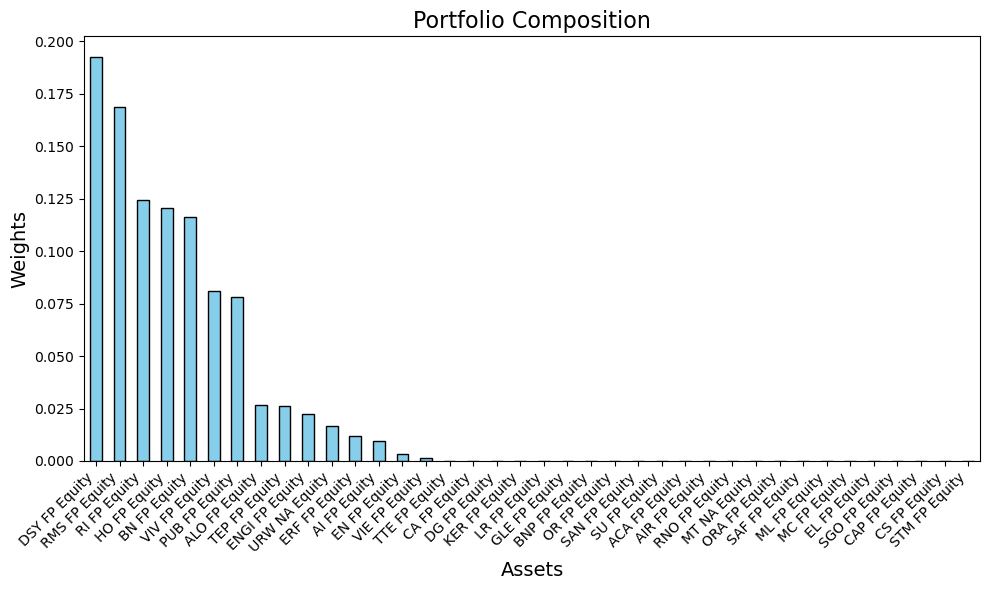


6. Efficient frontier visualization
--------------------------------------------------


/var/folders/9h/g7kp790x7_d8yvgr15gq4prr0000gp/T/ipykernel_1978/2839634822.py:107: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.annotate(txt, (vols_actions[i], returns_actions[i]))


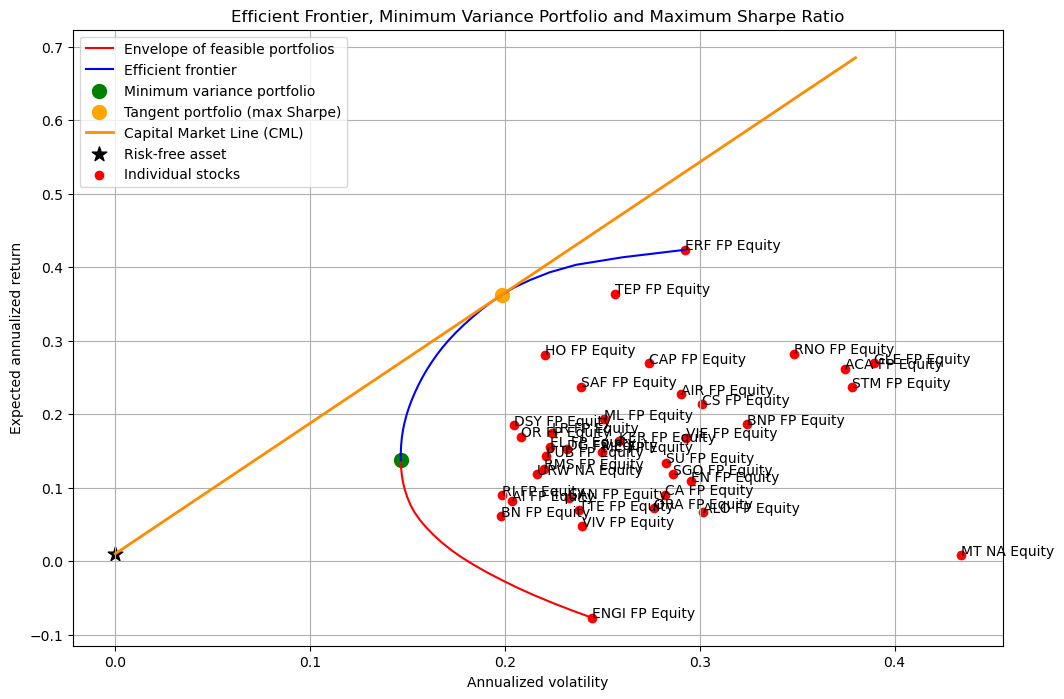

{'returns':             OR FP Equity  DG FP Equity  URW NA Equity  TTE FP Equity  \
 Dates                                                                  
 2012-01-02      0.013631      0.020438      -0.007919       0.012658   
 2012-01-03      0.003912      0.008853       0.003266       0.011125   
 2012-01-04     -0.009620     -0.005898      -0.011935      -0.007665   
 2012-01-05      0.001107     -0.014182      -0.015739      -0.006852   
 2012-01-06     -0.002948     -0.009542      -0.013760       0.003261   
 ...                  ...           ...            ...            ...   
 2016-12-26      0.000000      0.000000       0.000000       0.000000   
 2016-12-27      0.000869      0.000775       0.006093       0.000310   
 2016-12-28     -0.001737     -0.005269      -0.012113       0.007132   
 2016-12-29      0.001160      0.003116       0.013624      -0.001745   
 2016-12-30      0.004635      0.004814       0.015905       0.001748   
 
             AI FP Equity  DSY FP Equi

In [14]:
main()

## 10. Interpretation and going further

**Questions to discuss**

1. Which stocks have the highest / lowest betas? Does it make sense given their sector (banks, utilities, consumer staples…)?
2. Compare the CAPM expected returns with the historical annualised means: which stocks had a positive alpha over 2012–2016?
3. How many stocks receive a non-zero weight in the GMV portfolio? Why is the solution so concentrated?
4. Where does the tangency portfolio lie compared with the GMV? What is its Sharpe ratio, and how does it compare with the best individual stock's Sharpe ratio?
5. Are skewness and kurtosis consistent with a Gaussian assumption? What does it imply for variance as a risk measure?

**Limits of the approach**

- **Estimation error**: $\mu$ is estimated with huge noise (the standard error of an annual mean is $\sigma/\sqrt{\text{years}}$, e.g. $25\%/\sqrt5 \approx 11\%$!). The optimiser over-weights stocks whose mean was *overestimated* — Markowitz is sometimes called an "error maximiser".
- **In-sample**: the frontier is computed on the same data used to estimate $\mu$ and $\Sigma$; nothing guarantees these portfolios perform as well afterwards.
- **Stationarity**: volatilities and correlations change over time (correlations rise in crises).

**Extensions**

- Out-of-sample backtest: estimate on 2012–2016, measure the realised performance in 2017.
- Allow short selling (bounds $(-1, 1)$) and compare with the closed-form solution $\Sigma^{-1}\mathbf 1/(\mathbf 1^\top\Sigma^{-1}\mathbf 1)$.
- Replace the historical $\mu$ by the **CAPM expected returns** (or Black–Litterman), and $\Sigma$ by a **shrinkage** estimator (Ledoit–Wolf).
- Add maximum-weight constraints (e.g. $w_i \le 10\%$) to force diversification.
- Compute the tangency portfolio directly by maximising $S(w) = (w^\top\mu - r_f)/\sqrt{w^\top\Sigma w}$.